<a href="https://colab.research.google.com/github/zogydinesh/ITA-0616/blob/main/program13.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

Rows: 301  Columns: 9
  Car_Name  Year  Selling_Price  Present_Price  Kms_Driven Fuel_Type  \
0     ritz  2014           3.35           5.59       27000    Petrol   
1      sx4  2013           4.75           9.54       43000    Diesel   
2     ciaz  2017           7.25           9.85        6900    Petrol   
3  wagon r  2011           2.85           4.15        5200    Petrol   
4    swift  2014           4.60           6.87       42450    Diesel   

  Seller_Type Transmission  Owner  
0      Dealer       Manual      0  
1      Dealer       Manual      0  
2      Dealer       Manual      0  
3      Dealer       Manual      0  
4      Dealer       Manual      0   

Features used: ['Present_Price', 'Kms_Driven', 'Owner', 'Age', 'Fuel_Type_Diesel', 'Fuel_Type_Petrol', 'Seller_Type_Individual', 'Transmission_Manual'] 

Train size: 240  Test size: 61 

Test results (price in lakhs):
  MAE  = 1.023
  RMSE = 1.328
  R2   = 0.9013
  (Just guessing the average price gives MAE = 3.229)
Train R2 

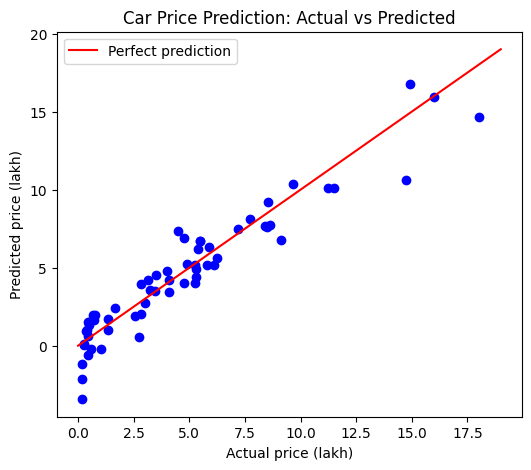

In [9]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# Dataset: Used Car Price data (CarDekho) - program13.csv, used as it is
# Selling_Price and Present_Price are in lakhs (1 lakh = 100,000 rupees)

# ---- 1. Load CSV ----
df = pd.read_csv('program13.csv')
print("Rows:", len(df), " Columns:", df.shape[1])
print(df.head(), "\n")

# ---- 2. Prepare features ----
df['Age'] = df['Year'].max() - df['Year']              # age of the car in years
y = df['Selling_Price'].values                         # what we want to predict
X_df = df.drop(columns=['Car_Name', 'Year', 'Selling_Price'])
X_df = pd.get_dummies(X_df, columns=['Fuel_Type', 'Seller_Type', 'Transmission'],
                      drop_first=True, dtype=float)    # text columns -> 0/1 columns
print("Features used:", list(X_df.columns), "\n")
X = X_df.values.astype(float)

# ---- 3. Train / test split (80% / 20%) ----
np.random.seed(42)
idx = np.random.permutation(len(X))
split = int(0.8 * len(X))
Xtr, Xte = X[idx[:split]], X[idx[split:]]
ytr, yte = y[idx[:split]], y[idx[split:]]
print("Train size:", len(Xtr), " Test size:", len(Xte), "\n")

# ---- 4. Standardize inputs (using training mean and std) ----
mu, sd = Xtr.mean(axis=0), Xtr.std(axis=0)
sd[sd == 0] = 1
Xtr_s = (Xtr - mu) / sd
Xte_s = (Xte - mu) / sd

# ---- 5. Train Multiple Linear Regression (least squares) ----
A = np.column_stack([np.ones(len(Xtr_s)), Xtr_s])       # add a column of 1s for the intercept
w = np.linalg.lstsq(A, ytr, rcond=None)[0]

def predict(Xs):
    return np.column_stack([np.ones(len(Xs)), Xs]) @ w

# ---- 6. Evaluate ----
def metrics(actual, predicted):
    mae = np.mean(np.abs(actual - predicted))
    rmse = np.sqrt(np.mean((actual - predicted) ** 2))
    r2 = 1 - np.sum((actual - predicted) ** 2) / np.sum((actual - actual.mean()) ** 2)
    return mae, rmse, r2

mae, rmse, r2 = metrics(yte, predict(Xte_s))
base_mae = np.mean(np.abs(yte - ytr.mean()))
print("Test results (price in lakhs):")
print(f"  MAE  = {mae:.3f}")
print(f"  RMSE = {rmse:.3f}")
print(f"  R2   = {r2:.4f}")
print(f"  (Just guessing the average price gives MAE = {base_mae:.3f})")
print(f"Train R2 = {metrics(ytr, predict(Xtr_s))[2]:.4f}\n")

# ---- 7. Which features matter most ----
print("Feature weights (on standardized inputs):")
for name, wt in sorted(zip(X_df.columns, w[1:]), key=lambda t: -abs(t[1])):
    print(f"  {name:<22} {wt:+.3f}")

# ---- 8. Actual vs predicted ----
pred_te = predict(Xte_s)
print("\nActual vs Predicted (first 8 test cars, lakhs):")
for a, p in zip(yte[:8], pred_te[:8]):
    print(f"  Actual = {a:6.2f}   Predicted = {p:6.2f}")

# ---- 9. Predict price of a new car ----
new = pd.DataFrame([{'Present_Price': 8.0, 'Kms_Driven': 30000, 'Owner': 0, 'Age': 4,
                     'Fuel_Type': 'Petrol', 'Seller_Type': 'Dealer', 'Transmission': 'Manual'}])
new = pd.get_dummies(new, columns=['Fuel_Type', 'Seller_Type', 'Transmission'], dtype=float)
new = new.reindex(columns=X_df.columns, fill_value=0.0)  # same columns as training
price = predict(((new.values.astype(float)) - mu) / sd)[0]
print("\nNew car: showroom price 8.0 lakh, 30000 km, 4 years old, Petrol, Dealer, Manual")
print(f"Predicted selling price: {price:.2f} lakh")

# ---- 10. Plot ----
plt.figure(figsize=(6, 5))
plt.scatter(yte, pred_te, color='blue')
lim = [0, max(yte.max(), pred_te.max()) + 1]
plt.plot(lim, lim, color='red', label='Perfect prediction')
plt.xlabel('Actual price (lakh)')
plt.ylabel('Predicted price (lakh)')
plt.title('Car Price Prediction: Actual vs Predicted')
plt.legend()
plt.show()